# Grouped additive model: training-only results and explanations

[Open this notebook in Google Colab](https://colab.research.google.com/github/neelia26/rare-missense-xai/blob/feature/grouped-additive-model/notebooks/grouped_additive_model.ipynb)

This notebook displays the saved training-only results. Each variant receives one signed logit contribution from conservation, gene constraint, amino-acid properties and protein context. The intercept plus these four values reconstructs the model logit exactly. Validation and test outcomes are not loaded.

In [1]:
from pathlib import Path
import json, subprocess, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/neelia26/rare-missense-xai.git'
BRANCH = 'feature/grouped-additive-model'
if IN_COLAB:
    REPO_ROOT = Path('/content/rare-missense-xai')
    if not REPO_ROOT.exists():
        subprocess.run(['git', 'clone', '--branch', BRANCH, REPO_URL, str(REPO_ROOT)], check=True)
else:
    REPO_ROOT = Path.cwd().resolve()
    if REPO_ROOT.name == 'notebooks':
        REPO_ROOT = REPO_ROOT.parent
OUTPUT = REPO_ROOT / 'outputs/grouped_additive_model/02_grouped_additive'
BASELINE = REPO_ROOT / 'outputs/grouped_additive_model/01_logistic_baseline'
summary = json.loads((OUTPUT / 'run_summary.json').read_text())
baseline = json.loads((BASELINE / 'run_summary.json').read_text())
predictions = pd.read_csv(OUTPUT / 'oof_predictions_and_group_contributions.csv')
search = pd.read_csv(OUTPUT / 'hyperparameter_search.csv')
print(f"Loaded {len(predictions):,} training-only OOF explanations")
print('Validation loaded:', summary['validation_loaded'], '| Test loaded:', summary['test_loaded'])

Loaded 27,727 training-only OOF explanations
Validation loaded: False | Test loaded: False


## Selected configuration and predictive comparison

In [2]:
display(search.style.format({'mean_fold_mcc': '{:.4f}', 'sd_fold_mcc': '{:.4f}', 'median_best_epoch': '{:.0f}'}))
comparison = pd.DataFrame([
    {'Model': 'Logistic regression', **baseline['pooled_oof_metrics_at_selected_threshold']},
    {'Model': 'Grouped additive', **summary['pooled_oof_metrics_at_selected_threshold']},
])[['Model', 'mcc', 'roc_auc', 'pr_auc', 'brier', 'accuracy']]
display(comparison.style.format({c: '{:.4f}' for c in comparison.columns if c != 'Model'}))

,configuration,mean_fold_mcc,sd_fold_mcc,median_best_epoch
0,w8_l1_tanh_lr0.001_wd0.0001_d0,0.7455,0.0158,162
1,w16_l1_relu_lr0.001_wd0.0001_d0.1,0.7356,0.0166,80
2,w8_l1_relu_lr0.001_wd0.0001_d0,0.7322,0.0150,70
3,w4_l1_relu_lr0.001_wd0.0001_d0,0.7265,0.0134,99


,Model,mcc,roc_auc,pr_auc,brier,accuracy
0,Logistic regression,0.7221,0.9328,0.9254,0.1013,0.8609
1,Grouped additive,0.7452,0.9411,0.9346,0.0938,0.8725


## How to read the explanation

A positive group contribution pushes the model towards pathogenicity. A negative contribution pushes it towards benignity. A value near zero has little effect for that particular variant. Contribution size is measured on the logit scale and should not be interpreted as causality or as independent biological importance.

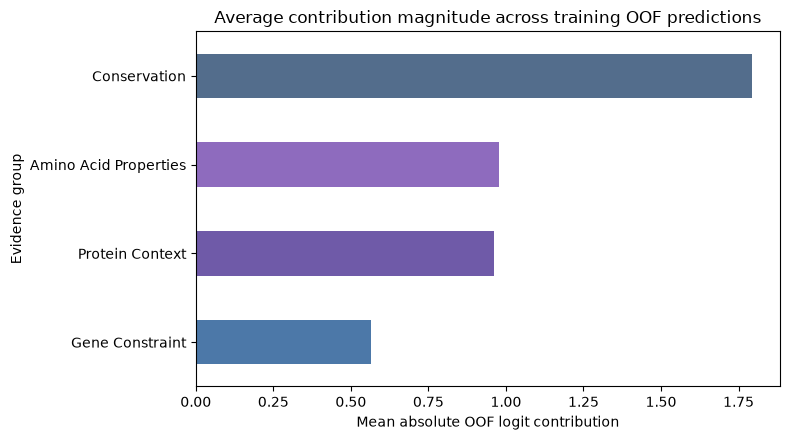

In [3]:
contribution_columns = [c for c in predictions if c.startswith('contribution_')]
labels = [c.replace('contribution_', '').replace('_', ' ').title() for c in contribution_columns]
mean_absolute = predictions[contribution_columns].abs().mean().sort_values()
ax = mean_absolute.plot.barh(figsize=(8, 4.5), color=['#4C78A8', '#6F5AA8', '#8E6BBE', '#536D8C'])
ax.set_xlabel('Mean absolute OOF logit contribution')
ax.set_ylabel('Evidence group')
ax.set_title('Average contribution magnitude across training OOF predictions')
ax.set_yticklabels([x.replace('contribution_', '').replace('_', ' ').title() for x in mean_absolute.index])
plt.tight_layout(); plt.show()

## Example variant-level explanations

In [4]:
examples = predictions.sort_values('probability').iloc[[0, len(predictions)//2, -1]].copy()
def direction(value):
    if value > 0.10: return 'supports pathogenicity'
    if value < -0.10: return 'supports benignity'
    return 'weak effect'
for _, row in examples.iterrows():
    print(f"\n{row['variant_key']} | {row['reconciled_gene_symbol']} | probability={row['probability']:.4f}")
    for column in contribution_columns:
        name = column.replace('contribution_', '').replace('_', ' ')
        print(f"  {name:24s} {row[column]:+7.3f}  ({direction(row[column])})")
    print(f"  reconstruction error: {row['reconstruction_error']:.2e}")


GRCh38:21:33550718:C:T | SON | probability=0.0002
  conservation              -3.099  (supports benignity)
  gene constraint           -1.381  (supports benignity)
  amino acid properties     -1.921  (supports benignity)
  protein context           -2.009  (supports benignity)
  reconstruction error: 2.12e-07

GRCh38:12:47984094:C:G | COL2A1 | probability=0.5525
  conservation              +2.173  (supports pathogenicity)
  gene constraint           +0.163  (supports pathogenicity)
  amino acid properties     -1.033  (supports benignity)
  protein context           -1.076  (supports benignity)
  reconstruction error: 8.20e-08

GRCh38:1:23804480:A:G | HMGCL | probability=0.9998
  conservation              +2.397  (supports pathogenicity)
  gene constraint           +1.019  (supports pathogenicity)
  amino acid properties     +1.897  (supports pathogenicity)
  protein context           +3.221  (supports pathogenicity)
  reconstruction error: 1.34e-07


## Biological evidence report

The report below adds the observed annotations, missing evidence and agreement or conflict between groups. It is deterministic and does not use an LLM to invent an interpretation.

In [5]:
from IPython.display import Markdown
report_path = REPO_ROOT / 'outputs/grouped_additive_model/03_evidence_reports/example_evidence_reports.md'
display(Markdown(report_path.read_text()))

# Example training out-of-fold evidence reports

## GRCh38:21:33550718:C:T (SON)

The training out-of-fold model predicted benign with probability 0.000. Conservation strongly supports benignity (-3.099 logit); observed annotations: phyloP=-1.78; PhastCons=0. Gene constraint strongly supports benignity (-1.381 logit); observed annotations: missense Z=2.59; LOEUF=0.051. Amino-acid properties strongly supports benignity (-1.921 logit); observed annotations: Grantham=64.4; hydropathy change=2.4; charge change=0; charge class changed=no; polarity class changed=no. Protein context strongly supports benignity (-2.009 logit); observed annotations: overlapping annotations: UniProt chain. The material evidence-group contributions agreed in supporting benignity. These statements describe the model's internal evidence contributions and do not establish causality or independent clinical evidence.

## GRCh38:12:47984094:C:G (COL2A1)

The training out-of-fold model predicted pathogenic with probability 0.553. Conservation moderately supports pathogenicity (+2.173 logit); observed annotations: phyloP=7.91; PhastCons=1. Gene constraint weakly supports pathogenicity (+0.163 logit); observed annotations: missense Z=5.39; LOEUF=0.183. Amino-acid properties moderately supports benignity (-1.033 logit); observed annotations: Grantham=60; hydropathy change=2.2; charge change=0; charge class changed=no; polarity class changed=no. Protein context moderately supports benignity (-1.076 logit); observed annotations: overlapping annotations: UniProt chain, UniProt region. The model contained conflicting evidence: Conservation supported pathogenicity, while Amino-acid properties, Protein context supported benignity. These statements describe the model's internal evidence contributions and do not establish causality or independent clinical evidence.

## GRCh38:1:23804480:A:G (HMGCL)

The training out-of-fold model predicted pathogenic with probability 1.000. Conservation moderately supports pathogenicity (+2.397 logit); observed annotations: phyloP=9.23; PhastCons=1. Gene constraint strongly supports pathogenicity (+1.019 logit); observed annotations: missense Z=0.336; LOEUF=1.03. Amino-acid properties strongly supports pathogenicity (+1.897 logit); observed annotations: Grantham=180; hydropathy change=-7; charge change=1; charge class changed=yes; polarity class changed=no. Protein context strongly supports pathogenicity (+3.221 logit); observed annotations: overlapping annotations: InterPro active site, InterPro domain, InterPro family, InterPro homologous superfamily, UniProt active site, UniProt chain, UniProt domain. The material evidence-group contributions agreed in supporting pathogenicity. These statements describe the model's internal evidence contributions and do not establish causality or independent clinical evidence.


## Faithfulness check

The saved explanation is faithful by construction because the model prediction uses the same four displayed contributions. The maximum numerical difference between the saved logit and the reconstructed logit is shown below.

In [6]:
faithfulness = pd.DataFrame({
    'Measure': ['Maximum reconstruction error', 'Required tolerance', 'Selected OOF threshold'],
    'Value': [summary['maximum_oof_reconstruction_error'], summary['reconstruction_tolerance'], summary['selected_threshold']]
})
display(faithfulness)

,Measure,Value
0,Maximum reconstruction error,7.823110e-07
1,Required tolerance,1.000000e-05
2,Selected OOF threshold,5.000000e-01
